# Load data

In [46]:
import numpy as np
import pandas as pd
import torch
from sklearn import preprocessing
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN, HDBSCAN, AgglomerativeClustering
from sklearn.metrics import homogeneity_score
from sklearn.decomposition import PCA

In [47]:
# Load the file using the path exactly as it was saved
file_path = 'embeddings_171225_2176_32768_blocks.28.mlp.l3' 
data = torch.load(file_path, map_location=torch.device('cpu'))

# Extract the lists from the dictionary
ids = data["ids"]               # List of strings
# DeepPL files contains accession id without version number, so we need to erase it from our ids
ids = [item.split('.')[0] for item in ids] 
embeddings_list = data["embeddings"] # List of torch.Tensors

# Stack the list of tensors into one large tensor (N_samples x 4096)
embeddings_tensor = torch.stack(embeddings_list)

# Convert to Numpy array
loaded_embeds = embeddings_tensor.detach().cpu().numpy()
loaded_ids = np.array(ids)

print("Embeddings shape:", loaded_ids.shape)
print("Embeddings shape:", loaded_embeds.shape) 

Embeddings shape: (2176,)
Embeddings shape: (2176, 4096)


In [48]:
# From data create a DataFrame
df = pd.DataFrame(data=loaded_embeds[:,:],    # values
              index=loaded_ids[:],    # 1st column as index
              columns=[[f"feature_{i}" for i in range(len(loaded_embeds[0]))]]) 
# Take a look
df.head()

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,...,feature_4086,feature_4087,feature_4088,feature_4089,feature_4090,feature_4091,feature_4092,feature_4093,feature_4094,feature_4095
NC_012663,190.00,-378.0,-284.0,376.0,420.0000,-162.000,-472.0,171.00,-314.0,-1024.0,...,-170.000,134.0000,-246.0,-264.00,-260.00,322.000,350.0,-456.0,-266.00,-30.250
NC_025467,58.25,-94.0,-83.5,96.5,103.0000,-48.750,-115.5,43.75,-69.0,-276.0,...,-51.000,38.0000,-58.0,-56.75,-55.50,100.000,83.0,-121.0,-23.75,-24.125
AJ298298,80.00,-170.0,-140.0,364.0,-11.3125,-48.500,-360.0,41.75,-230.0,-392.0,...,-57.000,28.5000,-119.5,-111.50,-72.00,28.375,81.0,-306.0,-132.00,-10.875
NC_025436,580.00,-868.0,-556.0,840.0,904.0000,-276.000,-1000.0,364.00,-676.0,-2160.0,...,-438.000,318.0000,-516.0,-656.00,-524.00,912.000,936.0,-1080.0,38.00,-164.000
NC_018269,47.00,-79.0,-82.0,88.0,35.0000,-11.375,-112.5,28.00,-93.5,-171.0,...,-29.125,12.3125,-69.5,-52.25,-54.25,45.500,81.5,-107.0,-55.75,-21.375


In [49]:
# Scale data
scaler = preprocessing.StandardScaler()
scaler.fit(df)
df_scaled = scaler.transform(df)
print(f'Shape of data: {df.shape}')
df_scaled

Shape of data: (2176, 4096)


array([[-0.16073947,  0.10331534,  0.17606649, ...,  0.17553224,
        -0.56381625,  0.51025   ],
       [-0.7829562 ,  0.881333  ,  0.97926134, ...,  0.94545406,
         0.7200107 ,  0.5496119 ],
       [-0.6802373 ,  0.6731311 ,  0.7529246 , ...,  0.5202733 ,
         0.14632952,  0.6347622 ],
       ...,
       [-0.40632027,  0.47588718,  0.44446576, ...,  0.48809752,
         0.13043073,  0.34637582],
       [ 0.7271296 , -1.0198792 , -0.9456021 , ..., -0.8724808 ,
        -1.3375572 ,  0.08449849],
       [-0.6613465 ,  0.7087446 ,  0.7649425 , ...,  0.55244917,
        -0.00205916,  1.1095153 ]], shape=(2176, 4096), dtype=float32)

In [50]:
# # Training
# sheet_names = pd.ExcelFile("journal.pcbi.1012525.s001.xlsx").sheet_names
# # Training dataset
# training = pd.read_excel("journal.pcbi.1012525.s001.xlsx", sheet_name=sheet_names[0])
# # Test dataset
# test = pd.read_excel("journal.pcbi.1012525.s001.xlsx", sheet_name=sheet_names[1])

# # Training data
# data_accessions_training = training['Accession number'].to_list()
# data_lifecycle_training = training['Lifecycle'].to_list()
# # Correct wrong spelled 
# data_lifecycle_training = [
#     "Lysogenic" if str(val).strip().lower() in ["lysogneic", "lysogenic"] 
#     else "lytic" 
#     for val in data_lifecycle_training
# ]
# # Test data
# data_accessions_test = test['Accession number'].to_list()
# data_lifecycle_test = test['Lifecycle'].to_list()

# print(f"Number of training elements: {len([ids[i] for i in range(len(ids)) if ids[i] in data_accessions_training])}")
# print(f'Number of test elements: {len([ids[i] for i in range(len(ids)) if ids[i] in data_accessions_test])}')
# #data_accession = data_accessions_training.extend(data_accessions_test)
# data_accession = data_accessions_training + data_accessions_test
# data_lifecycle = data_lifecycle_training + data_lifecycle_test
# print(len(data_accession))
# print(len(data_lifecycle))

In [51]:
# from sklearn.cluster import DBSCAN

# from sklearn.decomposition import PCA
# # Reduce from 4096 to 50 features
# pca = PCA(n_components=20)
# df_pca = pca.fit_transform(df_scaled)

# # Now run DBSCAN or K-Means on df_pca instead of df_scaled
# #clustering_pca = DBSCAN(eps=3, min_samples=5).fit(df_pca) # eps will need retuning

# clustering = DBSCAN(eps=10, min_samples=10).fit(df_pca)
# print(f'Number of clusters: {np.unique_counts(clustering.labels_).values.size}')

In [52]:
# # For each cluster, count the number of elements and then provide a percentage of 
# # virulent and dferate nodes
# # Key are clusters id, values are counts of elements in the respective cluster
# counts = {}
# #print(np.unique_counts(clustering.labels_))
# unique_clustering_labels = np.unique_counts(clustering.labels_).values
# clustering_counts = np.unique_counts(clustering.labels_).counts
# for i in range(len(unique_clustering_labels)):
#     counts[int(unique_clustering_labels[i])] = int(clustering_counts[i])

# # Create dictionaries for counts of lytic and lysogenic
# lytic_count = dict.fromkeys(counts.keys(), 0)
# lysogenic_count = dict.fromkeys(counts.keys(), 0)

# for i in range(len(clustering.labels_)):
#     if (data_lifecycle[i].strip().lower() == 'lysogenic'):
#         lysogenic_count[clustering.labels_[i]] += 1
#     else:
#         lytic_count[clustering.labels_[i]] += 1

In [53]:
# #df.index[0]

# # Ensure we process clusters in order (e.g., -1, 0, 1...)
# sorted_cluster_ids = sorted(counts.keys())

# data_matrix = []

# for cluster_id in sorted_cluster_ids:
#     total_elements = counts[cluster_id]
    
#     # Avoid division by zero if a cluster somehow has 0 elements
#     if total_elements > 0:
#         lytic_ratio = lytic_count[cluster_id] / total_elements
#         lysogenic_ratio = lysogenic_count[cluster_id] / total_elements
#     else:
#         lytic_ratio = 0.0
#         lysogenic_ratio = 0.0

#     data_matrix.append({
#         'Cluster': cluster_id,
#         'Lytic_Ratio': lytic_ratio,
#         'Lysogenic_Ratio': lysogenic_ratio,
#         'Total_Count': total_elements  # Optional: helpful context to see cluster size
#     })

# # Create the DataFrame
# df_ratios = pd.DataFrame(data_matrix)
# df_ratios.set_index('Cluster', inplace=True)

# # Display the matrix
# print(df_ratios)

# # Optional: Verify that rows sum to 1 (or close to it due to floating point)
# print("\nRow Sums check (should be ~1.0):")
# print(df_ratios[['Lytic_Ratio', 'Lysogenic_Ratio']].sum(axis=1))

In [54]:
# # Setup style
# sns.set_theme(style="whitegrid")
# plt.figure(figsize=(12, 6))

# # Plotting
# # We simply plot the 'Lytic' and 'Lysogenic' columns. 
# # Pandas integrates with Matplotlib to handle the stacking automatically.
# ax = df_ratios[['Lytic_Ratio', 'Lysogenic_Ratio']].plot(
#     kind='bar', 
#     stacked=True, 
#     figsize=(12, 6), 
#     color=['#e74c3c', '#2ecc71'], # Custom colors: Red (Lytic), Green (Lysogenic)
#     width=0.8
# )

# # Prettifying
# plt.title("Phage Lifecycle Composition per Cluster", fontsize=16, pad=20)
# plt.xlabel("Cluster ID", fontsize=12)
# plt.ylabel("Proportion", fontsize=12)
# plt.legend(title='Lifecycle', loc='upper right', frameon=True)
# plt.xticks(rotation=0) # Keep cluster IDs horizontal
# plt.ylim(0, 1) # Ensure y-axis is strictly 0 to 1

# # Optional: Add a horizontal line at 0.5 to show the "majority" crossover
# plt.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5)

# plt.tight_layout()
# plt.show()

In [55]:
# plt.figure(figsize=(6, 6))

# # Create the heatmap
# # annot=True puts the numbers in the cells
# # fmt=".2%" formats the numbers as percentages (e.g., 50.00%)
# # cmap="RdBu_r" creates a diverging color map (Red for Lytic, Blue for Lysogenic)
# sns.heatmap(
#     df_ratios[['Lytic_Ratio', 'Lysogenic_Ratio']], 
#     annot=True, 
#     fmt=".1%", 
#     cmap="RdYlGn_r", # Red to Green colormap (Red=High Lytic, Green=High Lysogenic)
#     linewidths=.5, 
#     cbar_kws={'label': 'Proportion'}
# )

# plt.title("Cluster Lifecycle Dominance Heatmap", fontsize=16, pad=20)
# plt.ylabel("Cluster ID", fontsize=12)
# plt.xlabel("Lifecycle", fontsize=12)

# plt.tight_layout()
# plt.show()

# Data Preparation

In [56]:
# --- CONFIGURATION ---
# Training
sheet_names = pd.ExcelFile("journal.pcbi.1012525.s001.xlsx").sheet_names
# Training dataset
training = pd.read_excel("journal.pcbi.1012525.s001.xlsx", sheet_name=sheet_names[0])
# Test dataset
test = pd.read_excel("journal.pcbi.1012525.s001.xlsx", sheet_name=sheet_names[1])


MIN_COVERAGE = 0.50  # Only keep results where >50% of data is clustered (not noise)
PCA_COMPONENTS = 30

# --- PREPARATION (Alignment) ---
# Create a dictionary mapping Accession ID -> Corrected Lifecycle
lifecycle_map = {}
all_metadata = pd.concat([training, test])

for _, row in all_metadata.iterrows():
    acc = row['Accession number']
    raw_life = row['Lifecycle']
    clean_life = "lysogenic" if str(raw_life).strip().lower() in ["lysogneic", "lysogenic"] else "lytic"
    lifecycle_map[acc] = clean_life

# Create aligned list
aligned_lifecycles = []
for accession in df.index:
    if accession in lifecycle_map:
        aligned_lifecycles.append(lifecycle_map[accession])
    else:
        # Warning only once per missing ID to avoid clutter
        print(f"Warning: Accession {accession} not found. Defaulting to lytic.")
        aligned_lifecycles.append("lytic") 

aligned_lifecycles = np.array(aligned_lifecycles)
print(f"Aligned labels length: {len(aligned_lifecycles)}")

# APPLY PCA
print(f"Applying PCA to reduce dimensions from {df_scaled.shape[1]} to {PCA_COMPONENTS}...")
#pca = PCA(n_components=PCA_COMPONENTS)
#df_pca = pca.fit_transform(df_scaled)
df_pca = df_scaled

# Check how much information (variance) is retained
#explained_variance = np.sum(pca.explained_variance_ratio_)
#print(f"Explained Variance retained: {explained_variance:.2%}")

Aligned labels length: 2176
Applying PCA to reduce dimensions from 4096 to 30...


# DBSCAN

In [57]:
# # GRID SEARCH
# eps_values = np.arange(3, 20, 1)        
# min_samples_values = range(5, 20, 1)    

# results = []

# print(f"Starting Grid Search (Filtering for Coverage > {MIN_COVERAGE:.0%})...")

# for eps in eps_values:
#     for min_samples in min_samples_values:
#         # Run DBSCAN
#         db = DBSCAN(eps=eps, min_samples=min_samples)
#         # labels = db.fit_predict(df_scaled)
#         labels = db.fit_predict(df_pca)
        
#         # Filter out noise (-1)
#         mask = labels != -1
#         n_clustered = np.sum(mask)
        
#         # Skip if everything is noise
#         if n_clustered == 0:
#             continue 

#         # Calculate Coverage
#         coverage = n_clustered / len(labels)
        
#         # SKIP if coverage is not "reasonable"
#         if coverage < MIN_COVERAGE:
#             continue

#         # Apply the mask to the labels  
#         clean_labels = labels[mask]
#         clean_lifecycles = aligned_lifecycles[mask]

#         # Calculate Score
#         score = homogeneity_score(clean_lifecycles, clean_labels)
        
#         # Store valid result
#         results.append({
#             'eps': eps, 
#             'min_samples': min_samples, 
#             'homogeneity': score,
#             'coverage': coverage,
#             'n_clusters': len(set(clean_labels))
#         })

# # --- RESULTS ---
# df_results = pd.DataFrame(results)

# if not df_results.empty:
#     # Sort primarily by Homogeneity, secondarily by Coverage
#     df_results = df_results.sort_values(by=['homogeneity', 'coverage'], ascending=[False, False])
    
#     print("\nTop 10 Valid Configurations:")
#     print(df_results.head(10))
    
#     # Get best
#     best_row = df_results.iloc[0]
#     print(f"\nBest Parameters: eps={best_row['eps']}, min_samples={best_row['min_samples']}")
#     print(f"Score: {best_row['homogeneity']:.4f}, Coverage: {best_row['coverage']:.2%}")
# else:
#     print("No configurations met the coverage threshold.")




from sklearn.metrics import homogeneity_score, completeness_score, v_measure_score

# GRID SEARCH DBSCAN
eps_values = np.arange(3, 20, 1)        
min_samples_values = range(5, 20, 1)    

results = []
print(f"Starting DBSCAN Grid Search (Filtering for Coverage > {MIN_COVERAGE:.0%})...")

for eps in eps_values:
    for min_samples in min_samples_values:
        db = DBSCAN(eps=eps, min_samples=min_samples)
        labels = db.fit_predict(df_pca)
        
        # Filter noise
        mask = labels != -1
        n_clustered = np.sum(mask)
        
        if n_clustered == 0: continue 

        coverage = n_clustered / len(labels)
        if coverage < MIN_COVERAGE: continue

        clean_labels = labels[mask]
        clean_lifecycles = aligned_lifecycles[mask]

        # Calculate ALL metrics
        h_score = homogeneity_score(clean_lifecycles, clean_labels)
        c_score = completeness_score(clean_lifecycles, clean_labels)
        v_score = v_measure_score(clean_lifecycles, clean_labels)
        
        results.append({
            'eps': eps, 
            'min_samples': min_samples, 
            'homogeneity': h_score,
            'completeness': c_score,
            'v_measure': v_score,
            'coverage': coverage,
            'n_clusters': len(set(clean_labels))
        })

df_dbscan = pd.DataFrame(results)
if not df_dbscan.empty:
    # Sort by V-Measure to balance Purity vs Grouping
    df_dbscan = df_dbscan.sort_values(by='v_measure', ascending=False)
    print("\nTop 10 DBSCAN Configurations (Sorted by V-Measure):")
    print(df_dbscan.head(10)[['eps', 'min_samples', 'n_clusters', 'coverage', 'homogeneity', 'v_measure']])

Starting DBSCAN Grid Search (Filtering for Coverage > 50%)...

Top 10 DBSCAN Configurations (Sorted by V-Measure):
    eps  min_samples  n_clusters  coverage  homogeneity  v_measure
7     6           10          13  0.505974     0.446684   0.257451
6     6            9          16  0.522978     0.462162   0.253266
1     5            6          36  0.505515     0.606530   0.244580
0     5            5          46  0.542279     0.607015   0.239189
2     6            5          47  0.639706     0.268257   0.127584
5     6            8          21  0.551011     0.213063   0.126911
3     6            6          32  0.598805     0.232561   0.123146
4     6            7          29  0.582261     0.226533   0.122708
11    7            8          22  0.624540     0.194741   0.118026
13    7           10          15  0.578585     0.174772   0.115641


# HDBSCAN

In [58]:
# # --- CONFIGURATION ---
# MIN_COVERAGE = 0.50  # Only keep results where >10% of data is clustered (not noise)

# # --- GRID SEARCH FOR HDBSCAN ---
# # min_cluster_size: The smallest grouping to be considered a split
# min_cluster_size_values = range(10, 30, 10) 
# # min_samples: larger values = more conservative (more noise)
# min_samples_values = range(5, 20, 5)    

# results = []

# print(f"Starting HDBSCAN Grid Search (Filtering for Coverage > {MIN_COVERAGE:.0%})...")

# for min_size in min_cluster_size_values:
#     for min_samples in min_samples_values:
        
#         # A. Run HDBSCAN
#         # cluster_selection_epsilon=0.0 merges clusters closer than this distance (optional)
#         clusterer = HDBSCAN(min_cluster_size=min_size, min_samples=min_samples, copy=True)
#         labels = clusterer.fit_predict(df_pca)
        
#         # Filter out noise (-1)
#         mask = labels != -1
#         n_clustered = np.sum(mask)
        
#         if n_clustered == 0:
#             continue 

#         # Calculate Coverage
#         coverage = n_clustered / len(labels)
        
#         # Skip if coverage is too low
#         if coverage < MIN_COVERAGE:
#             continue
            
#         clean_labels = labels[mask]
#         clean_lifecycles = aligned_lifecycles[mask] 
        
#         # Calculate Score
#         score = homogeneity_score(clean_lifecycles, clean_labels)
        
#         # Store result
#         results.append({
#             'min_cluster_size': min_size, 
#             'min_samples': min_samples, 
#             'homogeneity': score,
#             'coverage': coverage,
#             'n_clusters': len(set(clean_labels))
#         })

# # --- RESULTS ---
# df_results_hdbscan = pd.DataFrame(results)

# if not df_results_hdbscan.empty:
#     # Sort primarily by Homogeneity, secondarily by Coverage
#     df_results_hdbscan = df_results_hdbscan.sort_values(by=['homogeneity', 'coverage'], ascending=[False, False])
    
#     print("\nTop 10 Valid HDBSCAN Configurations:")
#     print(df_results_hdbscan.head(10))
    
#     best_row = df_results_hdbscan.iloc[0]
#     print(f"\nBest Parameters: min_cluster_size={best_row['min_cluster_size']}, min_samples={best_row['min_samples']}")
#     print(f"Score: {best_row['homogeneity']:.4f}, Coverage: {best_row['coverage']:.2%}")
# else:
#     print("No configurations met the coverage threshold.")



# GRID SEARCH HDBSCAN
min_cluster_size_values = range(10, 30, 10) 
min_samples_values = range(5, 20, 5)    

results = []
print(f"Starting HDBSCAN Grid Search (Filtering for Coverage > {MIN_COVERAGE:.0%})...")

for min_size in min_cluster_size_values:
    for min_samples in min_samples_values:
        
        clusterer = HDBSCAN(min_cluster_size=min_size, min_samples=min_samples, copy=True)
        labels = clusterer.fit_predict(df_pca)
        
        mask = labels != -1
        n_clustered = np.sum(mask)
        
        if n_clustered == 0: continue 

        coverage = n_clustered / len(labels)
        if coverage < MIN_COVERAGE: continue
            
        clean_labels = labels[mask]
        clean_lifecycles = aligned_lifecycles[mask] 
        
        # Calculate ALL metrics
        h_score = homogeneity_score(clean_lifecycles, clean_labels)
        c_score = completeness_score(clean_lifecycles, clean_labels)
        v_score = v_measure_score(clean_lifecycles, clean_labels)
        
        results.append({
            'min_cluster_size': min_size, 
            'min_samples': min_samples, 
            'homogeneity': h_score,
            'completeness': c_score,
            'v_measure': v_score,
            'coverage': coverage,
            'n_clusters': len(set(clean_labels))
        })

df_hdbscan = pd.DataFrame(results)
if not df_hdbscan.empty:
    df_hdbscan = df_hdbscan.sort_values(by='v_measure', ascending=False)
    print("\nTop 10 HDBSCAN Configurations (Sorted by V-Measure):")
    print(df_hdbscan.head(10)[['min_cluster_size', 'min_samples', 'n_clusters', 'coverage', 'homogeneity', 'v_measure']])



Starting HDBSCAN Grid Search (Filtering for Coverage > 50%)...

Top 10 HDBSCAN Configurations (Sorted by V-Measure):
   min_cluster_size  min_samples  n_clusters  coverage  homogeneity  v_measure
0                10            5          51  0.548254     0.721626   0.204509
1                10           15          17  0.637408     0.196784   0.116313
4                20           15          11  0.665441     0.172372   0.110207
3                20           10          11  0.753676     0.160583   0.096608
2                20            5          13  0.789062     0.153475   0.088424


# Agglomerative Clustering

In [59]:
# # --- GRID SEARCH FOR AGGLOMERATIVE CLUSTERING ---

# # We want to test a range of cluster counts to see which best separates the lifecycles
# n_clusters_values = range(2, 30, 1)  # Try 2 up to 29 clusters
# linkage_values = ['ward', 'complete', 'average', 'single']

# results = []
# print("Starting Agglomerative Grid Search...")

# for linkage in linkage_values:
#     for n_k in n_clusters_values:
        
#         # Ward linkage only supports Euclidean distance
#         if linkage == 'ward':
#             metric = 'euclidean'
#         else:
#             metric = 'euclidean' # You could try 'cosine' or 'manhattan' here for non-ward linkages
        
#         # A. Run Agglomerative Clustering
#         agg = AgglomerativeClustering(n_clusters=n_k, linkage=linkage, metric=metric)
#         labels = agg.fit_predict(df_pca)
        
#         # B. Calculate Score
#         # No noise filtering needed because Agglomerative assigns all points
#         score = homogeneity_score(aligned_lifecycles, labels)
        
#         # C. Store result
#         results.append({
#             'n_clusters': n_k, 
#             'linkage': linkage, 
#             'metric': metric,
#             'homogeneity': score
#         })

# # --- RESULTS ---
# df_results_agg = pd.DataFrame(results)

# if not df_results_agg.empty:
#     # Sort by Homogeneity
#     df_results_agg = df_results_agg.sort_values(by='homogeneity', ascending=False)
    
#     print("\nTop 10 Agglomerative Configurations:")
#     print(df_results_agg.head(10))
    
#     best_row = df_results_agg.iloc[0]
#     print(f"\nBest Parameters: n_clusters={best_row['n_clusters']}, linkage='{best_row['linkage']}'")
#     print(f"Score (Homogeneity): {best_row['homogeneity']:.4f}")
    
#     # Optional: If you want to use the best model immediately
#     print("\nFitting best model for further analysis...")
#     best_model = AgglomerativeClustering(
#         n_clusters=int(best_row['n_clusters']), 
#         linkage=best_row['linkage'], 
#         metric=best_row['metric']
#     )
#     best_labels = best_model.fit_predict(df_pca)
# else:
#     print("No results generated.")

Starting Agglomerative Grid Search...

Top 10 Agglomerative Configurations (Sorted by V-Measure):
    n_clusters linkage  homogeneity  completeness  v_measure
26          28    ward     0.319835      0.073929   0.120098
27          29    ward     0.319835      0.073435   0.119445
19          21    ward     0.297702      0.074653   0.119372
13          15    ward     0.275049      0.075736   0.118768
14          16    ward     0.275049      0.075683   0.118704
15          17    ward     0.278510      0.075304   0.118553
16          18    ward     0.278598      0.075044   0.118239
20          22    ward     0.301221      0.073536   0.118213
21          23    ward     0.301221      0.073492   0.118157
17          19    ward     0.280886      0.074467   0.117724

Best Parameters: n_clusters=28, linkage='ward'
V-Measure: 0.1201

Visualizing best model...


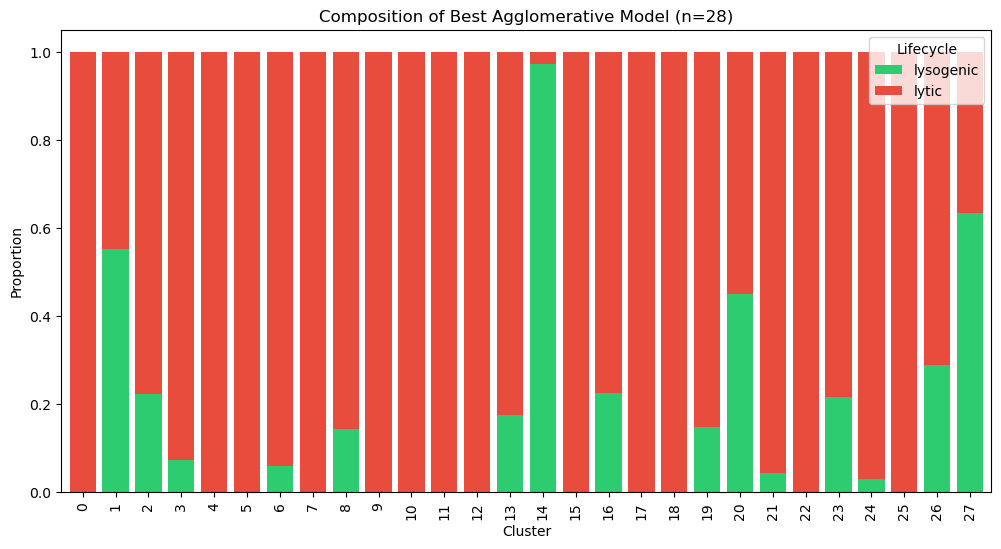

In [60]:
from sklearn.metrics import homogeneity_score, completeness_score, v_measure_score

# --- GRID SEARCH FOR AGGLOMERATIVE CLUSTERING ---

# We want to test a range of cluster counts 
n_clusters_values = range(2, 30, 1)  
linkage_values = ['ward', 'complete', 'average', 'single']

results = []
print("Starting Agglomerative Grid Search...")

for linkage in linkage_values:
    for n_k in n_clusters_values:
        
        if linkage == 'ward':
            metric = 'euclidean'
        else:
            metric = 'euclidean' 
        
        # A. Run Agglomerative Clustering
        agg = AgglomerativeClustering(n_clusters=n_k, linkage=linkage, metric=metric)
        labels = agg.fit_predict(df_pca)
        
        # B. Calculate Scores
        # V-Measure balances Homogeneity (purity) and Completeness (grouping)
        h_score = homogeneity_score(aligned_lifecycles, labels)
        c_score = completeness_score(aligned_lifecycles, labels)
        v_score = v_measure_score(aligned_lifecycles, labels)
        
        results.append({
            'n_clusters': n_k, 
            'linkage': linkage, 
            'metric': metric,
            'homogeneity': h_score,
            'completeness': c_score,
            'v_measure': v_score # <--- Look at this to pick the best trade-off
        })

# --- RESULTS ---
df_results_agg = pd.DataFrame(results)

if not df_results_agg.empty:
    # Sort by V-Measure (Balanced Score) instead of just Homogeneity
    df_results_agg = df_results_agg.sort_values(by='v_measure', ascending=False)
    
    print("\nTop 10 Agglomerative Configurations (Sorted by V-Measure):")
    print(df_results_agg.head(10)[['n_clusters', 'linkage', 'homogeneity', 'completeness', 'v_measure']])
    
    best_row = df_results_agg.iloc[0]
    print(f"\nBest Parameters: n_clusters={best_row['n_clusters']}, linkage='{best_row['linkage']}'")
    print(f"V-Measure: {best_row['v_measure']:.4f}")
    
    # --- VISUALIZE THE BEST MODEL ---
    print("\nVisualizing best model...")
    best_model = AgglomerativeClustering(
        n_clusters=int(best_row['n_clusters']), 
        linkage=best_row['linkage'], 
        metric=best_row['metric']
    )
    best_labels = best_model.fit_predict(df_pca)
    
    # Create the counts dataframe for plotting
    df_plot = pd.DataFrame({'Cluster': best_labels, 'Lifecycle': aligned_lifecycles})
    
    # Calculate ratios
    cross_tab = pd.crosstab(df_plot['Cluster'], df_plot['Lifecycle'], normalize='index')
    
    # Plot
    cross_tab.plot(
        kind='bar', 
        stacked=True, 
        figsize=(12, 6), 
        color=['#2ecc71', '#e74c3c'], # Adjust colors if needed (Green=Lysogenic, Red=Lytic)
        width=0.8
    )
    plt.title(f"Composition of Best Agglomerative Model (n={best_row['n_clusters']})")
    plt.ylabel("Proportion")
    plt.show()

else:
    print("No results generated.")

Data Split Loaded: 1804 Train, 372 Test

LOGISTIC REGRESSION REPORT
------------------------------------------------------------
Accuracy: 87.63%

Classification Report:
              precision    recall  f1-score   support

   lysogenic       0.95      0.68      0.79       127
       lytic       0.85      0.98      0.91       245

    accuracy                           0.88       372
   macro avg       0.90      0.83      0.85       372
weighted avg       0.89      0.88      0.87       372

Confusion Matrix:
[[ 86  41]
 [  5 240]]

RANDOM FOREST REPORT
------------------------------------------------------------
Accuracy: 90.32%

Classification Report:
              precision    recall  f1-score   support

   lysogenic       0.93      0.78      0.85       127
       lytic       0.89      0.97      0.93       245

    accuracy                           0.90       372
   macro avg       0.91      0.87      0.89       372
weighted avg       0.90      0.90      0.90       372

Confusion M

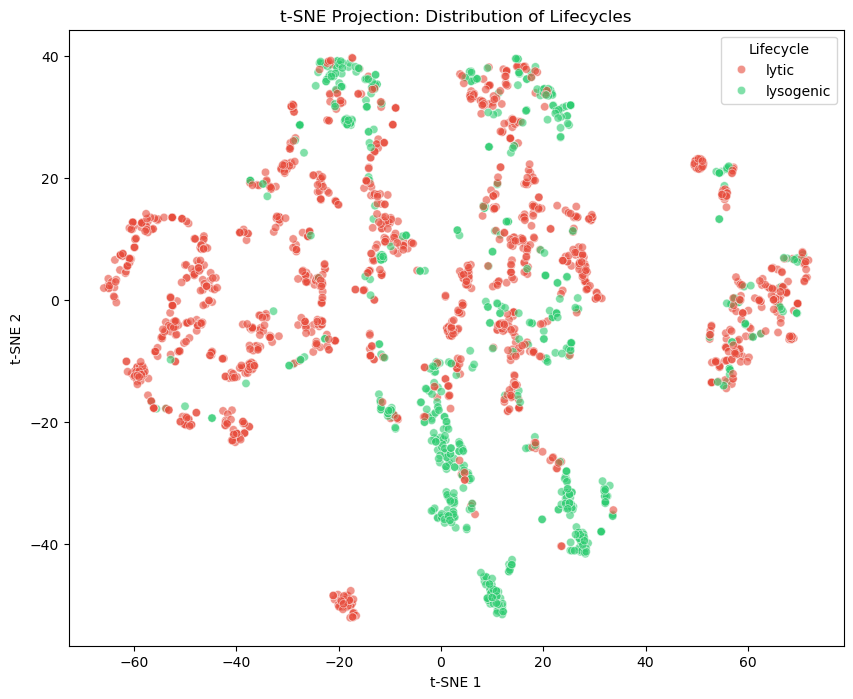

In [68]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.manifold import TSNE
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

RANDOM_STATE = 0

# --- 1. LOAD SPLIT DEFINITIONS ---
sheet_names = pd.ExcelFile("journal.pcbi.1012525.s001.xlsx").sheet_names
training_df = pd.read_excel("journal.pcbi.1012525.s001.xlsx", sheet_name=sheet_names[0])
test_df = pd.read_excel("journal.pcbi.1012525.s001.xlsx", sheet_name=sheet_names[1])

train_ids = set(training_df['Accession number'].astype(str).str.strip())
test_ids = set(test_df['Accession number'].astype(str).str.strip())

# --- 2. PREPARE FEATURES AND LABELS ---
train_indices = []
test_indices = []
y_train = []
y_test = []

for i, accession in enumerate(df.index):
    label = lifecycle_map.get(accession, "lytic")
    
    if accession in train_ids:
        train_indices.append(i)
        y_train.append(label)
    elif accession in test_ids:
        test_indices.append(i)
        y_test.append(label)

X_train = df_scaled[train_indices]
X_test = df_scaled[test_indices]
y_train = np.array(y_train)
y_test = np.array(y_test)

print(f"Data Split Loaded: {len(X_train)} Train, {len(X_test)} Test")

# --- 3. RUN CLASSIFICATION ---

# A. Logistic Regression
print("\n" + "="*60)
print("LOGISTIC REGRESSION REPORT")
print("-" * 60)
lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.2%}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_lr))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

# B. Random Forest
print("\n" + "="*60)
print("RANDOM FOREST REPORT")
print("-" * 60)
rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.2%}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_rf))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))
print("="*60)

# --- 4. VISUALIZATION (t-SNE) ---
print("\nGenerating t-SNE plot...")
tsne = TSNE(n_components=2, random_state=42, perplexity=30, init='pca', learning_rate='auto')
# Use PCA data if available for speed, else full scaled data
data_for_tsne = df_pca if 'df_pca' in locals() else df_scaled
X_embedded = tsne.fit_transform(data_for_tsne) 

df_viz = pd.DataFrame(X_embedded, columns=['t-SNE 1', 't-SNE 2'])
df_viz['Lifecycle'] = aligned_lifecycles 

plt.figure(figsize=(10, 8))
sns.scatterplot(
    data=df_viz, 
    x='t-SNE 1', 
    y='t-SNE 2', 
    hue='Lifecycle', 
    alpha=0.6, 
    palette={'lytic': '#e74c3c', 'lysogenic': '#2ecc71'}
)
plt.title("t-SNE Projection: Distribution of Lifecycles")
plt.show()

In [69]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, matthews_corrcoef

# --- 1. LOAD SPLIT DEFINITIONS ---
# (Assumes you have training_df and test_df loaded as before)
train_ids = set(training_df['Accession number'].astype(str).str.strip())
test_ids = set(test_df['Accession number'].astype(str).str.strip())

# --- 2. PREPARE DATA ---
train_indices = []
test_indices = []
y_train = []
y_test = []

for i, accession in enumerate(df.index):
    label = lifecycle_map.get(accession, "lytic")
    
    if accession in train_ids:
        train_indices.append(i)
        y_train.append(label)
    elif accession in test_ids:
        test_indices.append(i)
        y_test.append(label)

X_train = df_scaled[train_indices]
X_test = df_scaled[test_indices]
y_train = np.array(y_train)
y_test = np.array(y_test)

print(f"Data Split: {len(X_train)} Train, {len(X_test)} Test")

# --- 3. METRICS FUNCTION ---
def compute_and_print_metrics(model_name, y_true, y_pred, pos_label="lysogenic"):
    """
    Computes and prints detailed classification metrics.
    Assumes binary classification.
    """
    # Calculate standard metrics
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, pos_label=pos_label)
    mcc = matthews_corrcoef(y_true, y_pred)
    
    # Calculate Sensitivity and Specificity from Confusion Matrix
    # labels parameter ensures the matrix is always [TN FP]
    #                                               [FN TP]
    # We define the 'neg_label' based on what isn't the pos_label
    neg_label = "lytic" if pos_label == "lysogenic" else "lysogenic"
    
    cm = confusion_matrix(y_true, y_pred, labels=[neg_label, pos_label])
    tn, fp, fn, tp = cm.ravel()
    
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    
    print(f"\n{model_name} RESULTS")
    print("-" * 30)
    print(f"Sensitivity (Recall): {sensitivity:.4f}")
    print(f"Specificity:          {specificity:.4f}")
    print(f"Accuracy:             {acc:.4f}")
    print(f"F1-Score:             {f1:.4f}")
    print(f"MCC:                  {mcc:.4f}")
    print("-" * 30)
    print("Confusion Matrix:")
    print(f"                 Pred {neg_label}  Pred {pos_label}")
    print(f"Actual {neg_label:9} {tn:5d}           {fp:5d}")
    print(f"Actual {pos_label:9} {fn:5d}           {tp:5d}")

# --- 4. RUN MODELS ---

# A. Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
compute_and_print_metrics("LOGISTIC REGRESSION", y_test, y_pred_lr, pos_label="lysogenic")

# B. Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
compute_and_print_metrics("RANDOM FOREST", y_test, y_pred_rf, pos_label="lysogenic")

Data Split: 1804 Train, 372 Test

LOGISTIC REGRESSION RESULTS
------------------------------
Sensitivity (Recall): 0.6772
Specificity:          0.9796
Accuracy:             0.8763
F1-Score:             0.7890
MCC:                  0.7245
------------------------------
Confusion Matrix:
                 Pred lytic  Pred lysogenic
Actual lytic       240               5
Actual lysogenic    41              86

RANDOM FOREST RESULTS
------------------------------
Sensitivity (Recall): 0.7717
Specificity:          0.9714
Accuracy:             0.9032
F1-Score:             0.8448
MCC:                  0.7828
------------------------------
Confusion Matrix:
                 Pred lytic  Pred lysogenic
Actual lytic       238               7
Actual lysogenic    29              98
